Importing the libraries

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
import seaborn as sns
from sklearn import datasets

Importing the dataset

In [35]:
df=pd.read_csv('https://gist.githubusercontent.com/curran/a08a1080b88344b0c8a7/raw/0e7a9b0a5d22642a06d3d5b9bcbad9890c8ee534/iris.csv')

In [36]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [51]:
data=load_iris() #using inbuilt dataset

In [52]:
new_df=pd.DataFrame(data.data,columns=data.feature_names)

In [47]:
new_df.head(1)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2


In [48]:
data.target

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [50]:
df.species.unique()

array(['setosa', 'versicolor', 'virginica'], dtype=object)

In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


Label Encoding

In [54]:
from sklearn.preprocessing import LabelEncoder

In [55]:
enc=LabelEncoder()

In [61]:
df.species=enc.fit_transform(df.species)

In [62]:
df.species.unique()

array([0, 1, 2], dtype=int64)

In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [69]:
df.species.nunique()

3

In [73]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width,species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667,1.000000
std,0.828066,0.433594,1.764420,0.763161,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [74]:
df.corr()

,sepal_length,sepal_width,petal_length,petal_width,species
sepal_length,1.000000,-0.109369,0.871754,0.817954,0.782561
sepal_width,-0.109369,1.000000,-0.420516,-0.356544,-0.419446
petal_length,0.871754,-0.420516,1.000000,0.962757,0.949043
petal_width,0.817954,-0.356544,0.962757,1.000000,0.956464
species,0.782561,-0.419446,0.949043,0.956464,1.000000


<Axes: >

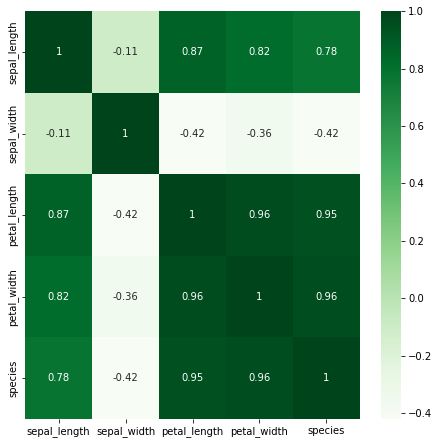

In [75]:
plt.figure(figsize=(7.5,7.5))
sns.heatmap(df.corr(),annot=True,cmap='Greens')

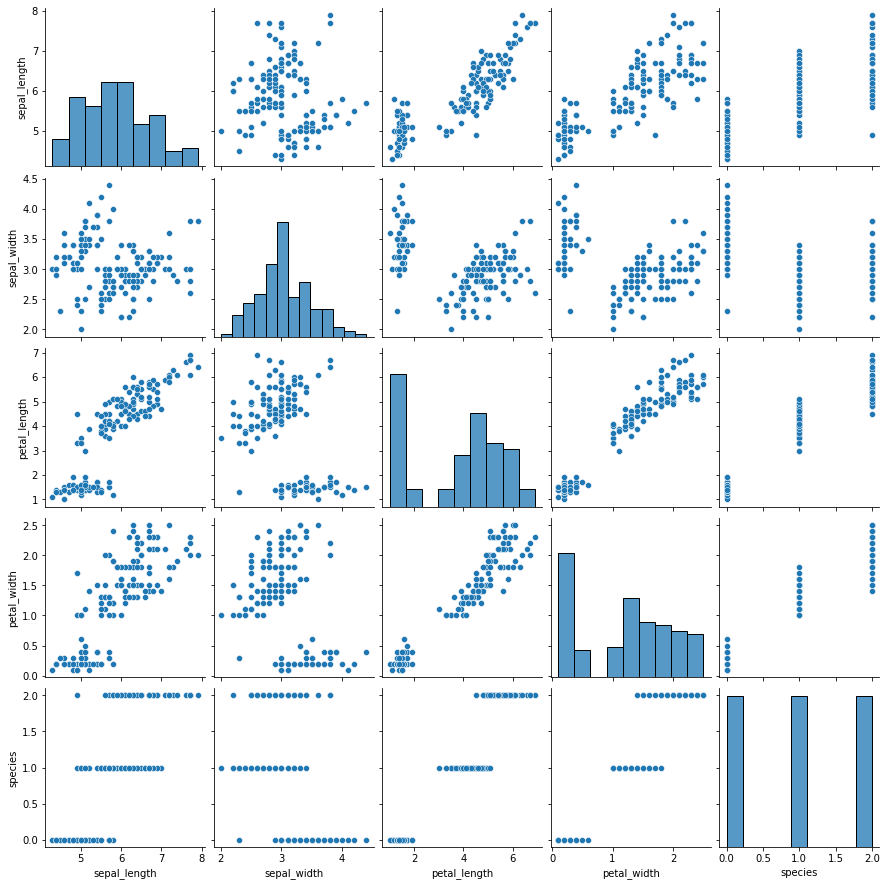

In [76]:
sns.pairplot(df)

Machine Learning

In [79]:
X=np.array(df.iloc[:,:-1].values)
Y=np.array(df.iloc[:,-1].values)

Splitting the data

In [84]:
from sklearn.model_selection import train_test_split

In [85]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.25,random_state=0)

Feature Scaling
- Standardization (MinMax Scaler)
- Normalization (Standard Scaler)

In [86]:
from sklearn.preprocessing import StandardScaler

In [87]:
sc=StandardScaler()

In [88]:
X_train=sc.fit_transform(X_train)
X_test=sc.fit_transform(X_test)

Choosing a model

In [89]:
from sklearn.linear_model import LogisticRegression

In [90]:
classifier=LogisticRegression()

Training the model

In [91]:
classifier.fit(X_train,Y_train)

LogisticRegression()

Hyperparameter Tuning

Parameters:
- penalty: Literal['l1', 'l2', 'elasticnet'] | None = "l2"
- dual: bool = False
- tol: Float = 0.0001
- C: Float = 1
- fit_intercept: bool = True
- intercept_scaling: Float = 1
- class_weight: Mapping | str | None = None
- random_state: Int | RandomState | None = None
- solver: Literal['lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'] = "lbfgs"
- max_iter: Int = 100
- multi_class: Literal['auto', 'ovr', 'multinomial'] = "auto"
- verbose: Int = 0
- warm_start: bool = False
- n_jobs: Int | None = None
- l1_ratio: Float | None = None

In [92]:
Y_pred=classifier.predict(X_test)

In [93]:
final_df=pd.DataFrame({'Actual':Y_test,'Predicted':Y_pred})

In [94]:
final_df.head()

,Actual,Predicted
0,2,2
1,1,1
2,0,0
3,2,2
4,0,0


<Axes: >

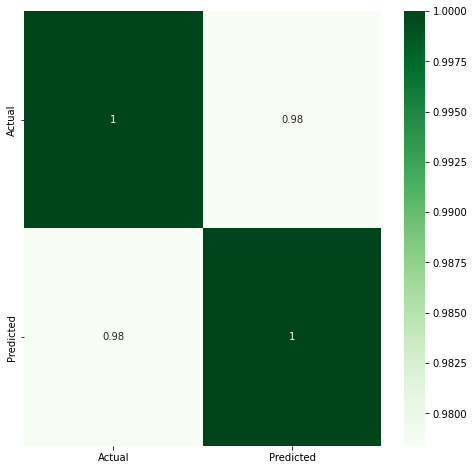

In [95]:
plt.figure(figsize=(8,8))
sns.heatmap(final_df.corr(),annot=True,cmap='Greens')

Testing the Accuracy

In [96]:
from sklearn.metrics import accuracy_score

In [97]:
accuracy_score(Y_test,Y_pred)

0.9736842105263158